# Nepal Flood & Weather Analysis
### Machine Learning Live Project Assessment

## 1. Import Libraries

In [139]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Train-test splitting and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Regression evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Classification evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Feature importance
from sklearn.inspection import permutation_importance

## 2. Load Dataset

In [140]:
df= pd.read_csv("/content/CORRECTED_2023_2026_NEPAL_FLOOD_WEATHER_KAGGLE.csv")
print(df)

                   date     location        river            basin  \
0      01-01-2023 00:00  Rasuwagadhi  Bhote Koshi         Narayani   
1      02-01-2023 00:00  Rasuwagadhi  Bhote Koshi         Narayani   
2      03-01-2023 00:00  Rasuwagadhi  Bhote Koshi         Narayani   
3      04-01-2023 00:00  Rasuwagadhi  Bhote Koshi         Narayani   
4      05-01-2023 00:00  Rasuwagadhi  Bhote Koshi         Narayani   
...                 ...          ...          ...              ...   
13385  31-08-2026 00:00    Chisapani      Karnali          Karnali   
13386  31-08-2026 00:00      Devghat     Narayani  Narayani/Gandak   
13387  31-08-2026 00:00      Khokana      Bagmati          Bagmati   
13388  31-08-2026 00:00        Kusum   West Rapti            Rapti   
13389  31-08-2026 00:00  Rasuwagadhi  Bhote Koshi         Narayani   

       dhm_station   latitude  longitude  elevation_m  precipitation_mm  \
0           446.22  28.271297  85.377649         1749               0.0   
1        

## 3. Initial Data Exploration

In [141]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13390 entries, 0 to 13389
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   date                         13390 non-null  object 
 1   location                     13390 non-null  object 
 2   river                        13390 non-null  object 
 3   basin                        13390 non-null  object 
 4   dhm_station                  13390 non-null  float64
 5   latitude                     13390 non-null  float64
 6   longitude                    13390 non-null  float64
 7   elevation_m                  13390 non-null  int64  
 8   precipitation_mm             13390 non-null  float64
 9   soil_moisture_0_100cm_m3m3   13390 non-null  float64
 10  rain_mm                      13390 non-null  float64
 11  temperature_mean_c           13390 non-null  float64
 12  dew_point_mean_c             13390 non-null  float64
 13  precipitation_ho

In [142]:
df.head()


,date,location,river,basin,dhm_station,latitude,longitude,elevation_m,precipitation_mm,soil_moisture_0_100cm_m3m3,rain_mm,temperature_mean_c,dew_point_mean_c,precipitation_hours,relative_humidity_mean_pct,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,river_discharge_m3s
0,01-01-2023 00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.315,0.0,12.2,-2.6,0,37,13.9,68.0,187,0.22
1,02-01-2023 00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.315,0.0,11.1,-4.8,0,34,13.4,69.8,191,0.21
2,03-01-2023 00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,11.5,-10.3,0,22,14.5,72.0,183,0.21
3,04-01-2023 00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,9.6,-8.9,0,29,11.2,67.7,187,0.20
4,05-01-2023 00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,10.1,-10.2,0,26,7.4,69.8,54,0.20


In [143]:
df.isnull().sum()

,0
date,0
location,0
river,0
basin,0
dhm_station,0
latitude,0
longitude,0
elevation_m,0
precipitation_mm,0
soil_moisture_0_100cm_m3m3,0


In [144]:
df.duplicated().sum()

np.int64(0)

In [145]:
df.columns

Index(['date', 'location', 'river', 'basin', 'dhm_station', 'latitude',
       'longitude', 'elevation_m', 'precipitation_mm',
       'soil_moisture_0_100cm_m3m3', 'rain_mm', 'temperature_mean_c',
       'dew_point_mean_c', 'precipitation_hours', 'relative_humidity_mean_pct',
       'wind_speed_max_kmh', 'wind_gusts_max_kmh',
       'wind_direction_dominant_deg', 'river_discharge_m3s'],
      dtype='object')

### Question 4: Analyze the Distribution of River Discharge

In [146]:
df["river_discharge_m3s"].describe()

,river_discharge_m3s
count,13390.000000
mean,20.372064
std,84.333629
min,0.000000
25%,0.260000
50%,1.880000
75%,10.530000
max,3175.870000


**Interpretation:**

The river discharge distribution is highly right-skewed. The mean discharge is 20.37 m³/s, while the median is 1.88 m³/s. Most discharge values are relatively low, but a few extremely high values reach 3175.87 m³/s. The high standard deviation (84.33 m³/s) indicates substantial variation in river discharge.

### Question 5: Identify the River Station or Location with the Highest Average River Discharge

In [147]:
df.groupby('location')['river_discharge_m3s'].mean()

,river_discharge_m3s
location,
Bahrabise,5.051314
Belsot,33.032636
Bhada Bridge,0.696617
Chameliya/Nayalbadi,31.393465
Chatara,1.491344
Chisapani,0.847072
Devghat,2.331277
Khokana,1.658006
Kusum,125.812158


In [148]:
df.groupby('basin')['river_discharge_m3s'].mean()

,river_discharge_m3s
basin,
Babai,0.696617
Bagmati,1.658006
Kamala,33.032636
Karnali,0.847072
Koshi,3.271329
Mahakali,31.393465
Narayani,1.406751
Narayani/Gandak,2.331277
Rapti,125.812158


**Interpretation:**

Kusum has the highest average river discharge (125.81 m³/s) among the analyzed locations. The Rapti basin also records the highest average discharge (125.81 m³/s) among the basins.

### Question 6: Analyze the Relationship Between Rainfall, Precipitation, and River Discharge

In [149]:
df[['temperature_mean_c', 'precipitation_mm', 'rain_mm',
    'relative_humidity_mean_pct', 'dew_point_mean_c',
    'wind_speed_max_kmh', 'wind_gusts_max_kmh','river_discharge_m3s']].corr()['river_discharge_m3s']

,river_discharge_m3s
temperature_mean_c,0.178499
precipitation_mm,0.098626
rain_mm,0.099743
relative_humidity_mean_pct,0.171687
dew_point_mean_c,0.226308
wind_speed_max_kmh,0.051560
wind_gusts_max_kmh,-0.009484
river_discharge_m3s,1.000000


### Question 7: Identify Which Weather Variable Has the Strongest Relationship with River Discharge

**Interpretation:**

Dew point (`dew_point_mean_c`) has the strongest positive correlation with river discharge (0.2263) among the analyzed weather variables. However, this indicates a weak positive linear relationship.

### Question 8: Compare River Discharge Across Different River Stations or Locations

**Interpretation:**

River discharge varies considerably across locations. Kusum has the highest average river discharge (125.81 m³/s), followed by Belsot (33.03 m³/s) and Chameliya/Nayalbadi (31.39 m³/s). Bhada Bridge has the lowest average discharge (0.70 m³/s).

These results indicate substantial differences in average river discharge across the monitored locations.

### Question 9: Analyze the Monthly or Seasonal Pattern of River Discharge

In [150]:
df['date'] = pd.to_datetime(df['date'], format='%d-%m-%Y %H:%M')

df['month'] = df['date'].dt.month
df['year'] = df['date'].dt.year
df['day'] = df['date'].dt.day

In [151]:
df=df.sort_values(by=['location','date'],ascending=True)


In [152]:
monthly_discharge = df.groupby('month')['river_discharge_m3s'].mean()
print(monthly_discharge)

month
1      4.309758
2      3.801097
3      3.533565
4      3.200350
5      3.251137
6      6.312908
7     53.719702
8     72.464669
9     52.970000
10    28.612140
11     8.743256
12     5.047118
Name: river_discharge_m3s, dtype: float64


**Interpretation:**

River discharge shows a clear seasonal pattern. The highest average discharge occurs in August (72.41 m³/s), followed by July (53.72 m³/s) and September (52.97 m³/s). The lowest average discharge occurs in April (3.20 m³/s).

River discharge increases significantly during July–September, which corresponds to the monsoon season in Nepal, and remains relatively low during the drier months.

### Question 10: Identify Periods with Unusually High River Discharge

In [153]:
threshold = df['river_discharge_m3s'].quantile(0.95)

high_discharge = df[df['river_discharge_m3s'] > threshold]

high_discharge[['date', 'dhm_station', 'river_discharge_m3s']]

,date,dhm_station,river_discharge_m3s
2048,2023-08-12,595.5,94.72
2049,2023-08-13,595.5,91.47
2050,2023-08-14,595.5,103.71
2051,2023-08-15,595.5,110.17
2052,2023-08-16,595.5,99.69
...,...,...,...
13348,2026-08-27,375.0,526.23
13358,2026-08-28,375.0,544.76
13368,2026-08-29,375.0,475.43
13378,2026-08-30,375.0,655.15


### Question 11: Create Lag Features for Rainfall (Previous 1, 2, and 3 Days)

In [154]:
df['rain_lag1']=df.groupby('location')['rain_mm'].shift(1)
df['rain_lag2']=df.groupby('location')['rain_mm'].shift(2)
df['rain_lag3']=df.groupby('location')['rain_mm'].shift(3)

### Question 12: Create Rolling Rainfall Features (3-Day and 7-Day Averages)

In [155]:
df['rolling_rainfall3']=(df.groupby('location')['rain_mm'].transform(lambda x:x.shift(1).rolling(window=3).mean()))
df['rolling_rainfall7']= (df.groupby('location')['rain_mm'].transform(lambda x: x.shift(1).rolling(window=7).mean()))


### Question 13: Create Previous-Day River Discharge Features

In [156]:
df['discharge_lag1']=df.groupby('location')['river_discharge_m3s'].shift(1)
df['discharge_lag2']=df.groupby('location')['river_discharge_m3s'].shift(2)
df['discharge_lag3']=df.groupby('location')['river_discharge_m3s'].shift(3)

### Question 14: Extract Useful Date Features Such as Year and Month


The year, month, and day features were already extracted from the date column during Question 9.

### Question 15: Encode the River Station/Location Variable for Machine Learning

Location encoding is performed after completing all location-based analysis and feature engineering, before preparing the input features for model training.

##  Machine Learning Prediction — Main Task

### Question 16: Create the Target Variable as the Next Day's River Discharge

In [157]:
df['next_day_discharge'] = (
    df.groupby('location')['river_discharge_m3s'].shift(-1)
)

### Data Preprocessing Before Model Training

After creating the lag features, rolling rainfall features, and next-day discharge target, missing values were checked and removed.

Duplicate records were also checked to ensure data quality.

The location variable was converted into numerical features using one-hot encoding to make it suitable for machine learning.

In [158]:
df.isnull().sum()

,0
date,0
location,0
river,0
basin,0
dhm_station,0
latitude,0
longitude,0
elevation_m,0
precipitation_mm,0
soil_moisture_0_100cm_m3m3,0


In [159]:
df['next_day_discharge'] = df['next_day_discharge'].fillna(df['next_day_discharge'].mean())
df = df.fillna(df.mean(numeric_only=True))


In [160]:
df.isnull().sum()

,0
date,0
location,0
river,0
basin,0
dhm_station,0
latitude,0
longitude,0
elevation_m,0
precipitation_mm,0
soil_moisture_0_100cm_m3m3,0


In [161]:
df.duplicated().sum()


np.int64(0)

In [162]:
df['location'].value_counts()

,count
location,
Bahrabise,1339
Belsot,1339
Bhada Bridge,1339
Chameliya/Nayalbadi,1339
Chatara,1339
Chisapani,1339
Devghat,1339
Khokana,1339
Kusum,1339


In [163]:
df=pd.get_dummies(df,columns=['location'],dtype=int)


### Question 17: Prepare the Input Features for Machine Learning

In [164]:

X=df.drop(columns=['date','river','basin','next_day_discharge'],axis=1)
y=df['next_day_discharge']
print(X.shape)
print(y.shape)

(13390, 36)
(13390,)


### Question 18: Split the Dataset Using a Time-Based Train-Test Split (80:20)

The dataset is split chronologically, using 80% of the unique dates for training and the remaining 20% for testing. A cutoff date is identified to ensure that earlier observations are used for training and later observations are used for testing.

In [165]:
dates = df['date'].sort_values().unique()
split_idx = int(len(dates) * 0.8)
cutoff_date = dates[split_idx]
print("Total unique dates:", len(dates))
print("Split index:", split_idx)
print("Cutoff date:", cutoff_date)

Total unique dates: 1339
Split index: 1071
Cutoff date: 2025-12-07 00:00:00


In [166]:
train_df = df[df['date'] < cutoff_date]
test_df = df[df['date'] >= cutoff_date]

In [167]:
X_train = X.loc[train_df.index]
X_test = X.loc[test_df.index]

y_train = y.loc[train_df.index]
y_test = y.loc[test_df.index]

In [168]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(10710, 36)
(2680, 36)
(10710,)
(2680,)


### Question 19: Explain Why a Time-Based Split Is More Appropriate Than a Random Split

**Interpretation:**

A time-based split is more appropriate because river discharge data follows a chronological sequence.

- A random split may mix past and future observations, increasing the risk of data leakage.
- A time-based split preserves chronological order by using earlier observations for training and later observations for testing.
- This approach provides a more realistic evaluation of the model's ability to predict future river discharge.

In this project, 10,710 records (80%) were used for training and 2,680 records (20%) for testing.

**Conclusion:** A time-based split is preferred because it maintains chronological order and reduces the risk of future-data leakage.

### Question 20: Train a Linear Regression Model to Predict Next-Day River Discharge

In [169]:
model=LinearRegression()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
print(y_pred)
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("RMSE:",np.sqrt(mean_squared_error(y_test,y_pred)))
print("R2:",r2_score(y_test,y_pred))

[ 0.09045106 -1.59692126 -0.79478984 ... 15.35727825 -0.20318713
  7.31479156]
MAE: 6.655813257571226
MSE: 331.87398222912543
RMSE: 18.21740876823939
R2: 0.9037904722637738


### Question 21: Train a Random Forest Regressor to Predict Next-Day River Discharge

In [170]:

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)
print(y_pred)
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("RMSE:",np.sqrt(mean_squared_error(y_test,y_pred)))
print("R2:",r2_score(y_test,y_pred))


[1.7278 1.6324 1.5834 ... 4.2062 3.9045 3.6235]
MAE: 2.8800547650759656
MSE: 510.1741855975261
RMSE: 22.587035785988522
R2: 0.8521016407195653


### Question 22: Train an Additional Regression Model — Decision Tree Regressor

In [171]:

dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
print("MAE:",mean_absolute_error(y_test,dt_pred))
print("MSE:",mean_squared_error(y_test,dt_pred))
print("RMSE:",np.sqrt(mean_squared_error(y_test,dt_pred)))
print("R2:",r2_score(y_test,dt_pred))


MAE: 3.438896332240145
MSE: 792.0772364689678
RMSE: 28.14386676469614
R2: 0.7703785746040122


### Question 23: Compare the Performance of Regression Models Using MAE, MSE, RMSE, and R²

### Interpretation

The performance of three regression models was compared using MAE, MSE, RMSE, and R² score.

| Model | MAE | MSE | RMSE | R² Score |
|---|---:|---:|---:|---:|
| Linear Regression | 6.6558 | 331.8740 | 18.2174 | 0.9038 |
| Random Forest Regressor | 2.8801 | 510.1742 | 22.5870 | 0.8521 |
| Decision Tree Regressor | 3.4389 | 792.0772 | 28.1439 | 0.7704 |

- **Linear Regression** achieved the highest R² score (0.9038) and the lowest MSE (331.8740) and RMSE (18.2174), indicating better overall performance on these metrics.

- **Random Forest Regressor** achieved the lowest MAE (2.8801), indicating the smallest average absolute prediction error. However, its higher RMSE suggests larger errors for some predictions.

- **Decision Tree Regressor** showed comparatively weaker performance, with the lowest R² score (0.7704) and the highest MSE (792.0772) and RMSE (28.1439).

### Conclusion

Linear Regression performed best based on R², MSE, and RMSE, while Random Forest Regressor achieved the lowest MAE.

### Question 24: Identify the Best-Performing Regression Model and Explain Why

### Interpretation

**Linear Regression** was identified as the best-performing regression model based on its R², MSE, and RMSE values.

- **R² Score:** 0.9038 (90.38%), the highest among the three models.
- **MSE:** 331.8740, the lowest among the three models.
- **RMSE:** 18.2174, the lowest among the three models.
- **MAE:** 6.6558.

Although Random Forest Regressor achieved the lowest MAE (2.8801), Linear Regression performed better in terms of R², MSE, and RMSE, indicating better overall performance when larger prediction errors are given more importance.

### Conclusion

Linear Regression was selected as the best-performing model for predicting next-day river discharge based on its higher R² score and lower MSE and RMSE values.

### Question 25: Visualize Actual vs. Predicted River Discharge



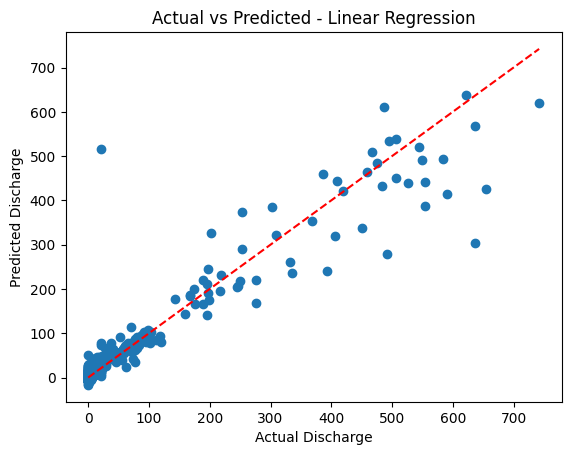

In [172]:

y_pred_lr = model.predict(X_test)

plt.scatter(y_test, y_pred_lr)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--')

plt.xlabel('Actual Discharge')
plt.ylabel('Predicted Discharge')
plt.title('Actual vs Predicted - Linear Regression')
plt.show()


### Question 26: Analyze Prediction Errors of the Best-Performing Regression Model

### Interpretation

The prediction errors of the Linear Regression model were analyzed using MAE, MSE, RMSE, and R² score.

- **MAE:** 6.6558 m³/s — The model's predictions differ from actual discharge values by approximately 6.66 m³/s on average.
- **MSE:** 331.8740 — Indicates the average squared prediction error, giving greater weight to larger errors.
- **RMSE:** 18.2174 m³/s — The higher RMSE compared to MAE suggests that some predictions have relatively large errors.
- **R² Score:** 0.9038 — The model explains approximately 90.38% of the variation in next-day river discharge.

### Conclusion

Linear Regression demonstrates strong overall predictive performance. However, the difference between MAE and RMSE indicates that some observations have larger prediction errors, particularly affecting the RMSE value.

### Question 27: Identify Dates or Locations Where the Model Made the Largest Prediction Errors

In [173]:
error_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred_lr
})

error_df['Absolute_Error'] = abs(error_df['Actual'] - error_df['Predicted'])

error_df.nlargest(10, 'Absolute_Error')

,Actual,Predicted,Absolute_Error
13388,20.383043,516.559911,496.176868
12948,637.260000,302.879567,334.380433
13368,655.150000,426.094770,229.055230
13128,491.040000,278.025176,213.014824
13308,590.560000,413.431941,177.128059
13178,553.630000,388.051867,165.578133
13208,393.460000,240.910848,152.549152
12988,201.300000,326.997637,125.697637
12968,486.530000,611.369706,124.839706
12958,742.020000,619.861245,122.158755


### Question 28: Identify the Most Important Features Affecting River Discharge Prediction

In [174]:


result = permutation_importance(
    model, X_test, y_test,
    n_repeats=5,
    random_state=42
)

importance = pd.Series(
    result.importances_mean,
    index=X_test.columns
)

print(importance.sort_values(ascending=False).head(10))

river_discharge_m3s    2.229032
discharge_lag1         0.349572
discharge_lag2         0.202483
longitude              0.041671
dhm_station            0.037759
rolling_rainfall3      0.031922
rain_mm                0.029821
precipitation_mm       0.021802
rain_lag1              0.013856
rain_lag3              0.009264
dtype: float64


### Interpretation

Permutation importance was used to identify the most important features in the Linear Regression model for predicting next-day river discharge.

- **Current river discharge (2.2290)** was the most important feature.
- **Discharge lag 1 (0.3496)** and **discharge lag 2 (0.2025)** were the next most important features.
- **Longitude (0.0417)** and **DHM station (0.0378)** also contributed to the predictions.
- Rainfall-related features, including rolling rainfall, rain and precipitation, showed relatively lower importance scores.

### Conclusion

Current and previous river discharge values were the most important predictive features for next-day discharge. Rainfall and location-related features contributed less to the model's predictions.

Feature importance indicates predictive contribution, not a direct cause-and-effect relationship.

### Question 29: Visualize Feature Importance





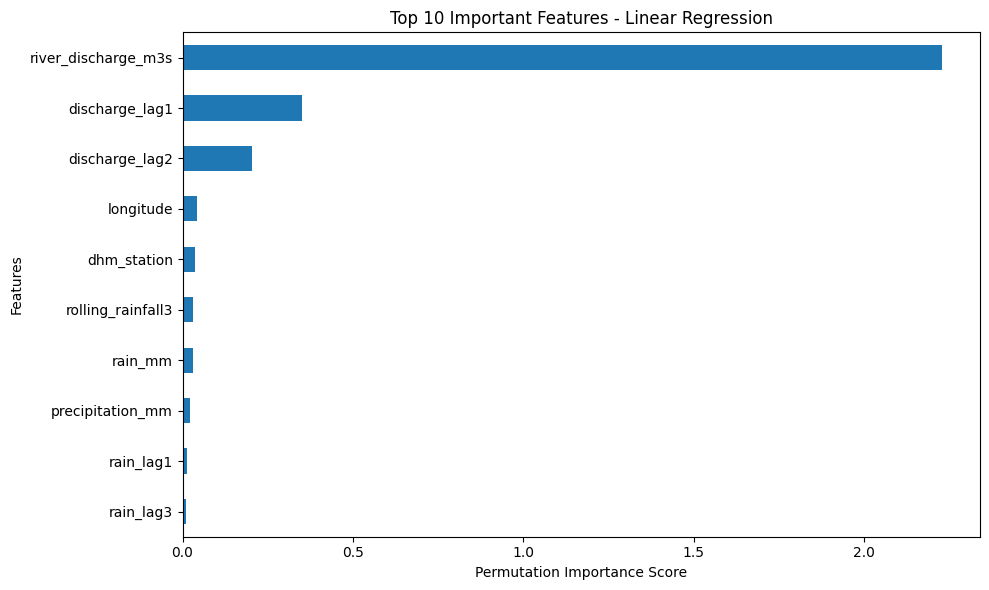

In [175]:
importance.sort_values(ascending=True).tail(10).plot(
    kind='barh',
    figsize=(10, 6)
)

plt.xlabel('Permutation Importance Score')
plt.ylabel('Features')
plt.title('Top 10 Important Features - Linear Regression')
plt.tight_layout()
plt.show()

### Question 30: Compare Model Performance Before and After Feature Engineering

In [176]:
df_before = df.drop(columns=[
    'month', 'year', 'day',
    'rain_lag1', 'rain_lag2', 'rain_lag3',
    'rolling_rainfall3', 'rolling_rainfall7',
    'discharge_lag1', 'discharge_lag2', 'discharge_lag3'
])
print(df_before.columns)

Index(['date', 'river', 'basin', 'dhm_station', 'latitude', 'longitude',
       'elevation_m', 'precipitation_mm', 'soil_moisture_0_100cm_m3m3',
       'rain_mm', 'temperature_mean_c', 'dew_point_mean_c',
       'precipitation_hours', 'relative_humidity_mean_pct',
       'wind_speed_max_kmh', 'wind_gusts_max_kmh',
       'wind_direction_dominant_deg', 'river_discharge_m3s',
       'next_day_discharge', 'location_Bahrabise', 'location_Belsot',
       'location_Bhada Bridge', 'location_Chameliya/Nayalbadi',
       'location_Chatara', 'location_Chisapani', 'location_Devghat',
       'location_Khokana', 'location_Kusum', 'location_Rasuwagadhi'],
      dtype='object')


In [177]:
X_before = df_before.drop(columns=['date', 'river', 'basin', 'next_day_discharge'])
y_before = df_before['next_day_discharge']

In [178]:
X_train_before = X_before.loc[train_df.index]
X_test_before = X_before.loc[test_df.index]

y_train_before = y_before.loc[train_df.index]
y_test_before = y_before.loc[test_df.index]

In [179]:
model_before = LinearRegression()
model_before.fit(X_train_before, y_train_before)

y_pred_before = model_before.predict(X_test_before)
print("MAE:", mean_absolute_error(y_test_before, y_pred_before))
print("MSE:", mean_squared_error(y_test_before, y_pred_before))
print("RMSE:", np.sqrt(mean_squared_error(y_test_before, y_pred_before)))
print("R2:", r2_score(y_test_before, y_pred_before))

MAE: 6.958207280759865
MSE: 372.5636588292769
RMSE: 19.301908165496926
R2: 0.8919946257103745


### Interpretation

The performance of the Linear Regression model was compared before and after feature engineering.

| Metric | Before Feature Engineering | After Feature Engineering |
|---|---:|---:|
| MAE | 6.9582 | 6.6558 |
| MSE | 372.5637 | 331.8740 |
| RMSE | 19.3019 | 18.2174 |
| R² Score | 0.8920 | 0.9038 |

After feature engineering:

- MAE decreased from 6.9582 to 6.6558.
- MSE decreased from 372.5637 to 331.8740.
- RMSE decreased from 19.3019 to 18.2174.
- R² increased from 0.8920 to 0.9038.

### Conclusion

Feature engineering improved the Linear Regression model's performance by reducing prediction errors and increasing the R² score. The additional lag, rolling rainfall, and date features contributed to better next-day river discharge prediction.

### Question 31: Create a High-Flow Classification Target

In [180]:
threshold = train_df.groupby('dhm_station')['river_discharge_m3s'].quantile(0.90)

df['threshold'] = df['dhm_station'].map(threshold)

df['high_flow'] = (df['river_discharge_m3s'] > df['threshold']).astype(int)

print(df[['dhm_station', 'river_discharge_m3s', 'threshold', 'high_flow']].head(10))

     dhm_station  river_discharge_m3s  threshold  high_flow
365        610.0                 1.05      13.66          0
366        610.0                 1.05      13.66          0
367        610.0                 1.01      13.66          0
368        610.0                 0.99      13.66          0
369        610.0                 0.97      13.66          0
370        610.0                 0.95      13.66          0
371        610.0                 0.94      13.66          0
372        610.0                 0.94      13.66          0
373        610.0                 0.92      13.66          0
374        610.0                 0.92      13.66          0


### Question 32: Handle Any Class Imbalance Appropriately

In [181]:
print(df.loc[train_df.index, 'high_flow'].value_counts())

high_flow
0    9643
1    1067
Name: count, dtype: int64


### Question 33: Train Logistic Regression, Decision Tree, and Random Forest Classification Models

In [182]:



X_log = df.drop(columns=[
    'date', 'river', 'basin',
    'next_day_discharge', 'high_flow','river_discharge_m3s', 'threshold'
])
y_log = df['high_flow']

X_train_log = X_log.loc[train_df.index]
X_test_log = X_log.loc[test_df.index]

y_train_log = y_log.loc[train_df.index]
y_test_log = y_log.loc[test_df.index]

# Feature scaling
scaler = StandardScaler()
X_train_log = scaler.fit_transform(X_train_log)
X_test_log = scaler.transform(X_test_log)

# Train model
log_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)
log_model.fit(X_train_log, y_train_log)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [183]:


# Features and target
X_dt = df.drop(columns=[
    'date', 'river', 'basin',
    'next_day_discharge', 'high_flow','river_discharge_m3s', 'threshold'
])
y_dt = df['high_flow']


X_train_dt = X_dt.loc[train_df.index]
X_test_dt = X_dt.loc[test_df.index]

y_train_dt = y_dt.loc[train_df.index]
y_test_dt = y_dt.loc[test_df.index]

# Train model
dt_model = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)
dt_model.fit(X_train_dt, y_train_dt)

DecisionTreeClassifier(class_weight='balanced', random_state=42)

In [184]:


# Features and target
X_rf = df.drop(columns=[
    'date', 'river', 'basin',
    'next_day_discharge', 'high_flow','river_discharge_m3s', 'threshold'
])
y_rf = df['high_flow']

X_train_rf = X_train_dt
X_test_rf = X_test_dt

y_train_rf = y_train_dt
y_test_rf = y_test_dt

# Train model
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)
rf_model.fit(X_train_rf, y_train_rf)

RandomForestClassifier(class_weight='balanced', random_state=42)

### Question 34: Evaluate Classification Models Using Accuracy, Precision, Recall, F1-Score, and Confusion Matrix

In [185]:


y_pred_log = log_model.predict(X_test_log)

print("Accuracy:", accuracy_score(y_test_log, y_pred_log))
print("Precision:", precision_score(y_test_log, y_pred_log))
print("Recall:", recall_score(y_test_log, y_pred_log))
print("F1 Score:", f1_score(y_test_log, y_pred_log))
print("Confusion Matrix:")
print(confusion_matrix(y_test_log, y_pred_log))

Accuracy: 0.8440298507462687
Precision: 0.29152542372881357
Recall: 1.0
F1 Score: 0.45144356955380577
Confusion Matrix:
[[2090  418]
 [   0  172]]


In [186]:
y_pred_dt = dt_model.predict(X_test_dt)

print("Accuracy:", accuracy_score(y_test_dt, y_pred_dt))
print("Precision:", precision_score(y_test_dt, y_pred_dt))
print("Recall:", recall_score(y_test_dt, y_pred_dt))
print("F1 Score:", f1_score(y_test_dt, y_pred_dt))
print("Confusion Matrix:")
print(confusion_matrix(y_test_dt, y_pred_dt))

Accuracy: 0.9264925373134328
Precision: 0.448559670781893
Recall: 0.6337209302325582
F1 Score: 0.5253012048192771
Confusion Matrix:
[[2374  134]
 [  63  109]]


In [187]:
y_pred_rf = rf_model.predict(X_test_rf)

print("Accuracy:", accuracy_score(y_test_rf, y_pred_rf))
print("Precision:", precision_score(y_test_rf, y_pred_rf))
print("Recall:", recall_score(y_test_rf, y_pred_rf))
print("F1 Score:", f1_score(y_test_rf, y_pred_rf))
print("Confusion Matrix:")
print(confusion_matrix(y_test_rf, y_pred_rf))

Accuracy: 0.9574626865671642
Precision: 0.7230769230769231
Recall: 0.5465116279069767
F1 Score: 0.6225165562913907
Confusion Matrix:
[[2472   36]
 [  78   94]]


### Question 35: Identify the Best Classification Model

**Interpretation:**

Random Forest was identified as the best overall classification model based on the updated evaluation results.

- **Accuracy:** 95.75%, the highest among the three models.
- **Precision:** 72.31%, the highest among the three models.
- **F1-Score:** 62.25%, the highest among the three models.
- **Recall:** 54.65%.

However, Logistic Regression achieved the highest recall (100%), detecting all 172 high-flow observations in the test dataset, but with 418 false positives.

**Conclusion:**

Random Forest was selected as the best overall classification model based on accuracy, precision, and F1-score. However, Logistic Regression is preferable when identifying all high-flow observations is the main priority, despite generating more false alarms.

### Question 36: Explain Which Features Contribute Most to High-Flow Predictions

In [188]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train_rf.columns
)
print(importance.sort_values(ascending=False).head(10))

rolling_rainfall7             0.126488
dew_point_mean_c              0.120858
discharge_lag1                0.106765
month                         0.091251
discharge_lag2                0.066366
soil_moisture_0_100cm_m3m3    0.061549
discharge_lag3                0.054826
rolling_rainfall3             0.051380
rain_lag2                     0.040459
relative_humidity_mean_pct    0.039455
dtype: float64


**Interpretation:**

Random Forest feature importance analysis identified the most influential features for high-flow classification.

- **7-day rolling rainfall (0.1265)** was the most important feature.
- **Mean dew point (0.1209)** was the second most important feature.
- **Discharge lag 1 (0.1068)** was the third most important feature.
- **Month (0.0913)** and **discharge lag 2 (0.0664)** also contributed to predictions.
- Soil moisture, discharge lag 3, and 3-day rolling rainfall showed additional importance.

**Conclusion:**

Historical rainfall, previous river discharge, and weather conditions were important predictive features for identifying high-flow observations.

Feature importance reflects the model's predictive reliance on these variables and does not establish causation.

### Question 37: Which Weather and Historical River Features Are Most Useful for Predicting Next-Day Discharge?

**Answer:**


Historical river discharge features were the most useful predictors of next-day river discharge.

- **Current river discharge** was the most important predictive feature.
- **Discharge lag 1 and lag 2** were also highly important, showing the value of previous discharge measurements.
- **Rainfall and precipitation** provided additional predictive information, but their importance was lower than historical discharge features.

**Conclusion:**

Current and historical river discharge values were the strongest predictors of next-day discharge, while weather-related features contributed additional information.

### Question 38: Which Machine Learning Model Gives the Best Prediction Performance?

**Answer:**

Two machine learning tasks were evaluated: regression for predicting next-day river discharge and classification for identifying high-flow observations.

- **Linear Regression** was the best-performing regression model based on R² (0.9038) and RMSE (18.2174).
- **Random Forest Regressor** achieved the lowest MAE (2.8801), but Linear Regression performed better in terms of R² and RMSE.
- **Random Forest Classifier** achieved the highest classification accuracy (95.75%) and F1-score (62.25%).
- **Logistic Regression Classifier** achieved 100% recall but generated more false positives.

**Conclusion:**

Linear Regression was selected as the preferred model for predicting continuous next-day river discharge, while Random Forest Classifier performed best overall for identifying high-flow observations based on accuracy and F1-score.

### Question 39: How Much Does Feature Engineering Improve the Model?

**Answer:**

Feature engineering improved the performance of the Linear Regression model for predicting next-day river discharge.

- **MAE** decreased from 6.9582 to 6.6558, a reduction of approximately 4.35%.
- **MSE** decreased from 372.5637 to 331.8740, a reduction of approximately 10.92%.
- **RMSE** decreased from 19.3019 to 18.2174, a reduction of approximately 5.62%.
- **R² Score** increased from 0.8920 to 0.9038.

**Conclusion:**

Feature engineering improved the model's predictive performance by reducing errors and increasing the R² score. The addition of lag features, rolling rainfall averages, and historical discharge information helped improve next-day river discharge prediction.

### Question 40: Which River Station Is the Easiest and Hardest for the Model to Predict?

In [189]:


# Create a DataFrame with test results
station_errors = pd.DataFrame({
    'dhm_station': df.loc[X_test.index, 'dhm_station'],
    'Actual': y_test,
    'Predicted': model.predict(X_test)
})

# Calculate absolute error
station_errors['Absolute_Error'] = abs(
    station_errors['Actual'] - station_errors['Predicted']
)

# Calculate average error for each station
station_mae = station_errors.groupby('dhm_station')['Absolute_Error'].mean()

# Sort from lowest to highest error
print(station_mae.sort_values())

dhm_station
446.22     2.986438
120.00     3.373194
610.00     3.663547
291.00     4.099648
550.05     4.185291
280.00     4.340878
595.50     4.554452
450.00     5.056385
695.00     5.149000
375.00    29.149300
Name: Absolute_Error, dtype: float64


### Question 41: What Are the Main Patterns Found in Rainfall and River Discharge?

**Answer:**

The analysis identified the following patterns in rainfall and river discharge:

- Rainfall and river discharge vary across monitoring stations and seasons.
- River discharge is generally higher during the monsoon months (July to September), with the highest average discharge in August.
- Current and historical river discharge values are the strongest predictors of next-day discharge.
- Rainfall lag features and rolling rainfall averages provide additional historical information for prediction.
- High-flow observations occur less frequently than normal-flow observations.

**Conclusion:**

River discharge shows seasonal and station-wise variations. Historical discharge and rainfall information are useful for predicting next-day river discharge, with historical discharge having the greatest predictive importance.



### Question 42: What Are the Limitations of Your Prediction Model?

**Answer:**
**Interpretation:**

The Nepal Flood & Weather Analysis models have the following limitations:

- **Extreme Flow Prediction:** The models may produce larger errors when predicting unusually high river discharge values.
- **Negative Predictions:** Linear Regression sometimes predicts negative discharge values, which are not physically possible.
- **Limited Input Features:** Factors such as dam operations and upstream water releases were not included in the dataset.
- **Station-Level Variations:** Prediction accuracy may differ across monitoring stations.
- **Class Imbalance:** High-flow observations are less frequent, making classification challenging. Random Forest achieved only 54.65% recall.
- **Data Imputation:** Filling missing values with the mean, including the prediction target, introduces estimated values that may affect model evaluation.
- **Model Generalization:** The models were evaluated using one chronological train-test split, and their performance on new stations has not been established.

**Conclusion:**

The models show promising performance, but improvements in extreme-flow prediction, data quality, and validation are needed to increase their reliability.